# Getting final dataset from HDFS

In [2]:
import os
import sys
import glob

os.environ["SPARK_HOME"] = "/usr/local/spark"
os.environ["PYSPARK_PYTHON"] = sys.executable

sys.path.insert(0, "/usr/local/spark/python")
sys.path.insert(
    0,
    glob.glob("/usr/local/spark/python/lib/py4j-*.zip")[0]
)

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("CA1_NeuralNetwork") \
    .getOrCreate()

print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/09 11:14:32 WARN Utils: Your hostname, BDSP, resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/10/09 11:14:32 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/09 11:14:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.1.2


In [3]:
# Load final labelled dataset

DATA_PATH = "hdfs://127.0.0.1:9000/ca1/processed/comments_labeled"

dataset = spark.read.parquet(DATA_PATH)

print("Rows:", dataset.count())
print("Columns:", len(dataset.columns))

dataset.printSchema()
dataset.show(5, truncate=80)

Rows: 108524
Columns: 11
root
 |-- comment_id: string (nullable = true)
 |-- video_id: string (nullable = true)
 |-- comment_text: string (nullable = true)
 |-- video_title: string (nullable = true)
 |-- video_description: string (nullable = true)
 |-- video_tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- video_age_at_comment: double (nullable = true)
 |-- comment_hour: integer (nullable = true)
 |-- comment_weekday: integer (nullable = true)
 |-- label: integer (nullable = true)
 |-- video_category: integer (nullable = true)

+--------------------------+-----------+----------------------------------------------+------------------------------------------------------------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+--------------------+------------+---------------+-----+--------------+
|                comment_id|   video_id|          

# EDA

In [1]:
# %pip install pandas seaborn scikit-learn tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-manylinux_2_27_x86_64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.0-cp314-cp314-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (7.6 kB)
  Using cached grpcio-1.84.0-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (3.8 kB)
  Using cached h5py-3.15.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cach

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 25.6 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26/26 [tensorflow]0m 25/26 [tensorflow]s-nightly]
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

df = dataset.toPandas()
df.head()

,comment_id,video_id,comment_text,video_title,video_description,video_tags,video_age_at_comment,comment_hour,comment_weekday,label,video_category
0,Ugw--xqQJI_vVrBJolp4AaABAg,pTENB-nPOLA,You did not even dip it because I see no sause,Dave's Hot Chicken vs Raising Cane's: Which On...,We brought Dave's Hot Chicken and Raising Cane...,"[sosoadventures, shorts, funny, food review, f...",11.814444,19,4,0,19
1,Ugw-0fkME2CPQ8f8TFx4AaABAg,mlJDEtoFeNo,bang gati ban nya yang gede,Jangan BERTINGKAH deh.. @mikejntk,,[],15.036667,4,1,0,19
2,Ugw-1s1P6wJMeGCbJiR4AaABAg,7rd6HWqvaHQ,OMG,The 10-Second Time Machine,This is a short film about a guy who finds a d...,[],1516.089444,18,7,0,19
3,Ugw-39XG_mTtUIRDK9V4AaABAg,JPNwr1dkkoE,Hornet got violated,How Japanese Bees Cook Hornets Alive 😮,,[],744.427778,20,4,0,19
4,Ugw-6YwyW8gCVtekjTJ4AaABAg,lfLNJzk0XFE,☭😊☭,How The Invisible Deck Works 🤔,,[],7.086944,2,1,0,19


In [10]:
df.shape

(108524, 11)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108524 entries, 0 to 108523
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   comment_id            108524 non-null  str    
 1   video_id              108524 non-null  str    
 2   comment_text          108524 non-null  str    
 3   video_title           108524 non-null  str    
 4   video_description     108524 non-null  str    
 5   video_tags            108524 non-null  object 
 6   video_age_at_comment  108524 non-null  float64
 7   comment_hour          108524 non-null  int32  
 8   comment_weekday       108524 non-null  int32  
 9   label                 108524 non-null  int32  
 10  video_category        108524 non-null  int32  
dtypes: float64(1), int32(4), object(1), str(5)
memory usage: 7.5+ MB


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

df['label'].value_counts()

label
0    103514
1      5010
Name: count, dtype: int64

# Label Variable Distribution

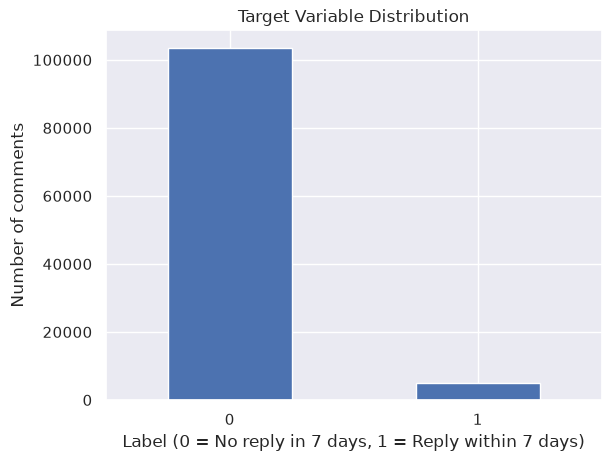

In [6]:
sns.set()
df['label'].value_counts().plot(kind='bar', rot=0)
plt.title('Target Variable Distribution')
plt.xlabel('Label (0 = No reply in 7 days, 1 = Reply within 7 days)')
plt.ylabel('Number of comments')
plt.show()

# Comment & Target Variable

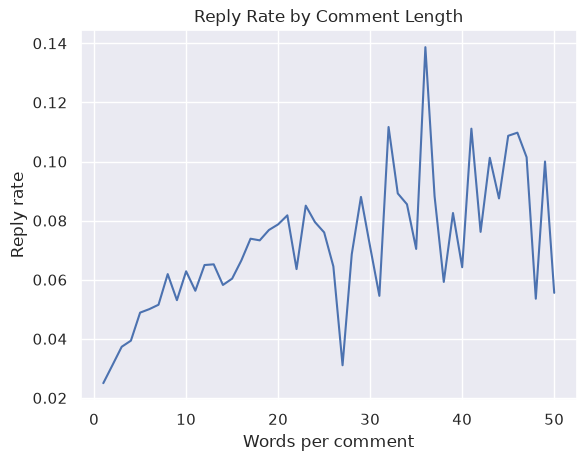

In [7]:
df['n_words'] = df['comment_text'].str.split().str.len()

df[df['n_words'] <= 50].groupby('n_words')['label'].mean().plot()
plt.title('Reply Rate by Comment Length')
plt.xlabel('Words per comment')
plt.ylabel('Reply rate')
plt.show()

# video_content & target variable 

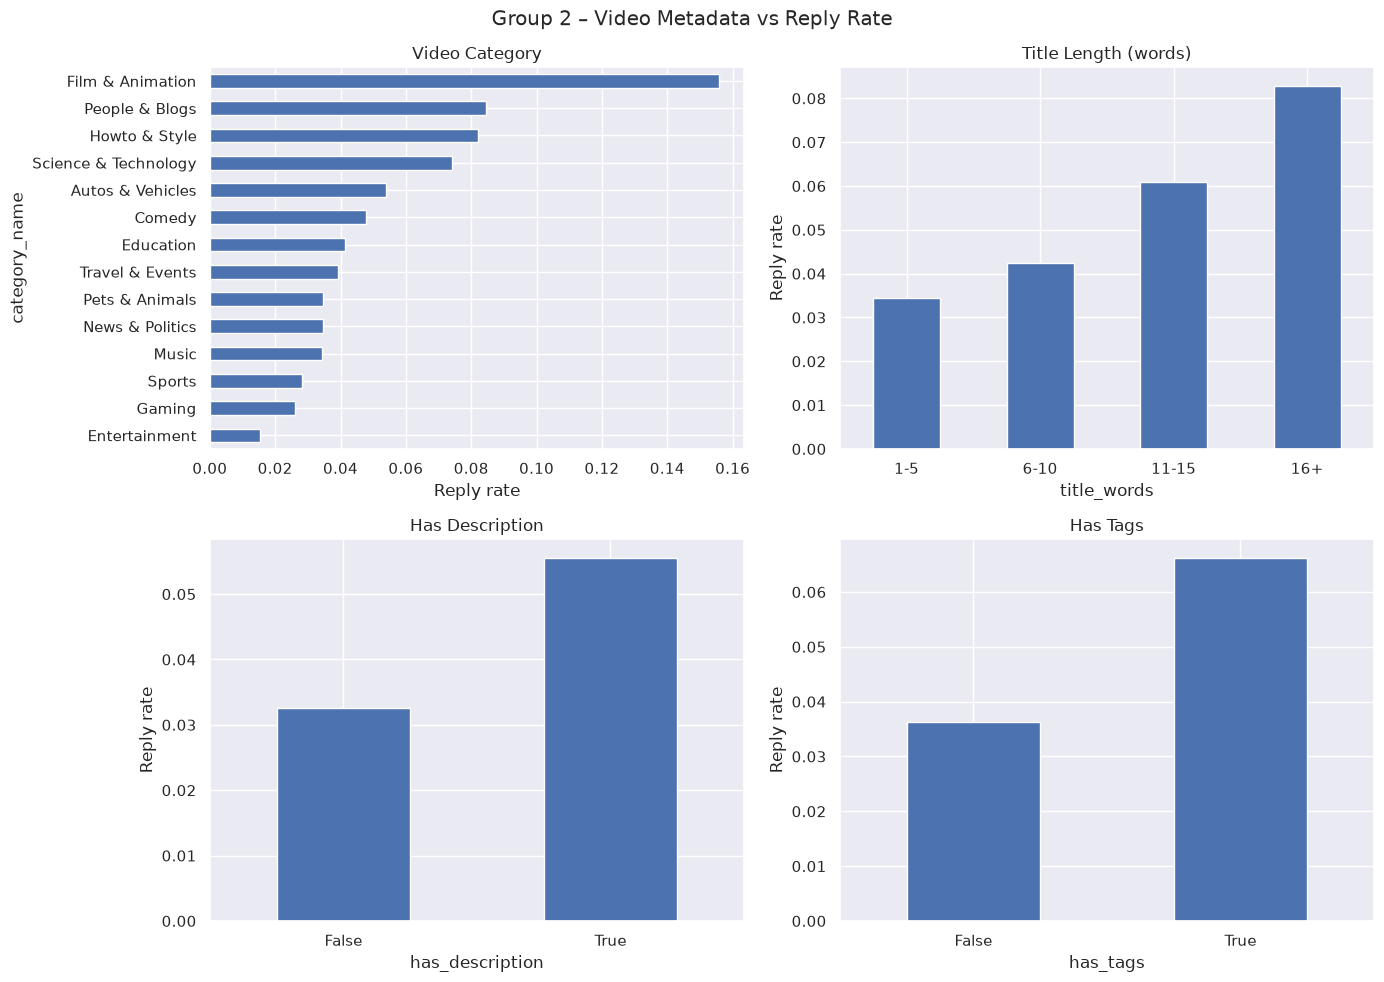

In [8]:
category_names = {1: "Film & Animation", 2: "Autos & Vehicles", 10: "Music",
                  15: "Pets & Animals", 17: "Sports", 19: "Travel & Events",
                  20: "Gaming", 22: "People & Blogs", 23: "Comedy",
                  24: "Entertainment", 25: "News & Politics", 26: "Howto & Style",
                  27: "Education", 28: "Science & Technology"}

df['category_name']   = df['video_category'].map(category_names)
df['title_words']     = pd.cut(df['video_title'].str.split().str.len(),
                               bins=[0, 5, 10, 15, 100], labels=['1-5', '6-10', '11-15', '16+'])
df['has_description'] = df['video_description'].str.strip() != ''
df['has_tags']        = df['video_tags'].str.len() > 0

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df.groupby('category_name')['label'].mean().sort_values().plot(kind='barh', ax=axes[0, 0])
axes[0, 0].set_title('Video Category')
axes[0, 0].set_xlabel('Reply rate')

df.groupby('title_words', observed=True)['label'].mean().plot(kind='bar', rot=0, ax=axes[0, 1])
axes[0, 1].set_title('Title Length (words)')
axes[0, 1].set_ylabel('Reply rate')

df.groupby('has_description')['label'].mean().plot(kind='bar', rot=0, ax=axes[1, 0])
axes[1, 0].set_title('Has Description')
axes[1, 0].set_ylabel('Reply rate')

df.groupby('has_tags')['label'].mean().plot(kind='bar', rot=0, ax=axes[1, 1])
axes[1, 1].set_title('Has Tags')
axes[1, 1].set_ylabel('Reply rate')

plt.suptitle('Group 2 – Video Metadata vs Reply Rate')
plt.tight_layout()
plt.show()

In [ ]:
# Model 3 temporal feature & target variable

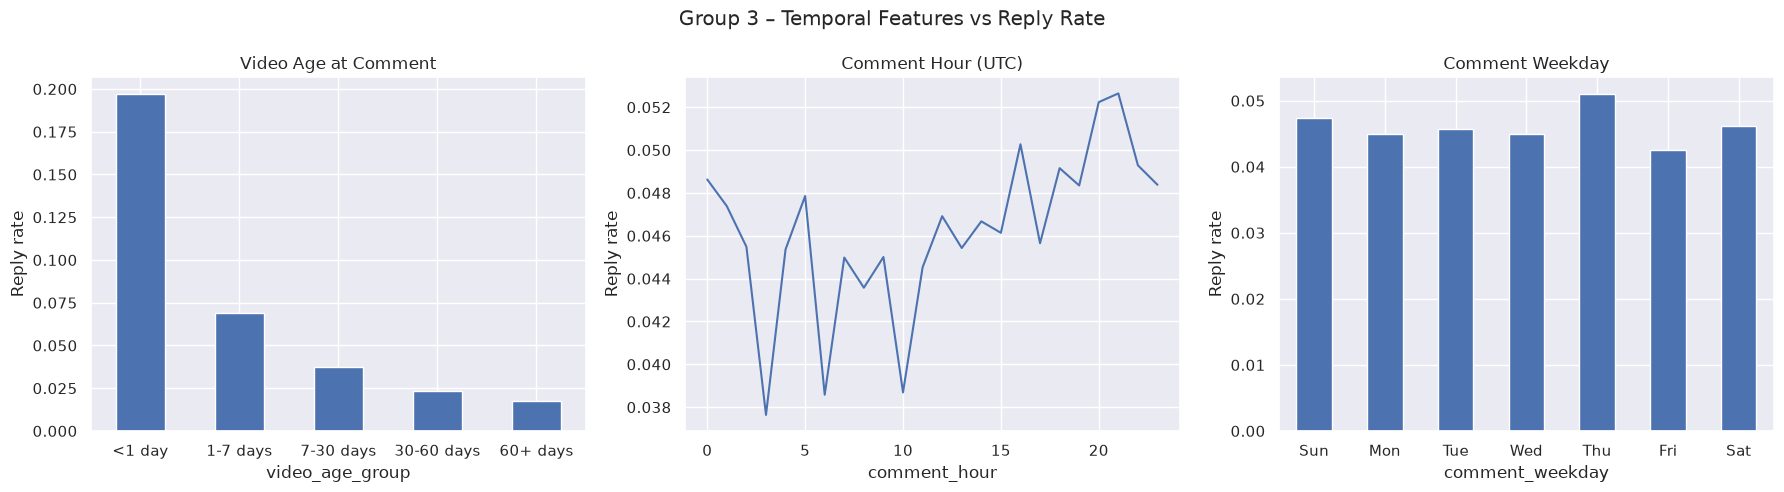

In [9]:
df['video_age_group'] = pd.cut(df['video_age_at_comment'] / 24,
                               bins=[0, 1, 7, 30, 60, 100],
                               labels=['<1 day', '1-7 days', '7-30 days', '30-60 days', '60+ days'],
                               include_lowest=True)

weekday_names = {1: 'Sun', 2: 'Mon', 3: 'Tue', 4: 'Wed', 5: 'Thu', 6: 'Fri', 7: 'Sat'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df.groupby('video_age_group', observed=True)['label'].mean().plot(kind='bar', rot=0, ax=axes[0])
axes[0].set_title('Video Age at Comment')
axes[0].set_ylabel('Reply rate')

df.groupby('comment_hour')['label'].mean().plot(ax=axes[1])
axes[1].set_title('Comment Hour (UTC)')
axes[1].set_ylabel('Reply rate')

df.groupby('comment_weekday')['label'].mean().rename(weekday_names).plot(kind='bar', rot=0, ax=axes[2])
axes[2].set_title('Comment Weekday')
axes[2].set_ylabel('Reply rate')

plt.suptitle('Group 3 – Temporal Features vs Reply Rate')
plt.tight_layout()
plt.show()

In [10]:
df['n_words'].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    108524.000000
mean          8.013499
std          15.287248
min           1.000000
50%           5.000000
75%           9.000000
90%          17.000000
95%          25.000000
99%          54.000000
max        1717.000000
Name: n_words, dtype: float64

In [11]:
video_text = df['video_title'] + ' ' + df['video_description'] + ' ' + df['video_tags'].str.join(' ')
video_text.str.split().str.len().describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

count    108524.000000
mean         72.614657
std         131.192338
min           2.000000
50%          22.000000
75%          81.000000
90%         177.000000
95%         302.000000
99%         800.000000
max         908.000000
dtype: float64

# Split Train - test- validation 
group-aware split by video_id was used to prevent data leakage, since video-level features are shared across comments of the same video

In [12]:
from sklearn.model_selection import GroupShuffleSplit

# 1) 70% train – 30% temp
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df['video_id']))
train_df = df.iloc[train_idx]
temp_df  = df.iloc[temp_idx]

# 2) temp -> 50% validation – 50% test
gss = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss.split(temp_df, groups=temp_df['video_id']))
val_df  = temp_df.iloc[val_idx]
test_df = temp_df.iloc[test_idx]

for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f"{name:<11} rows: {len(part):>6} | videos: {part['video_id'].nunique():>3} | positive: {part['label'].mean():.2%}")

Train       rows:  73929 | videos: 402 | positive: 4.30%
Validation  rows:  17076 | videos:  86 | positive: 6.45%
Test        rows:  17519 | videos:  87 | positive: 4.15%


In [ ]:
# Text Vectorization (Group 1: comment_text)

In [13]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

COMMENT_MAX_LEN = 30
VOCAB_SIZE = 20000

comment_vectorizer = TextVectorization(max_tokens=VOCAB_SIZE,
                                       output_sequence_length=COMMENT_MAX_LEN)
comment_vectorizer.adapt(train_df['comment_text'].values)

X_train_comment = comment_vectorizer(train_df['comment_text'].values)
X_val_comment   = comment_vectorizer(val_df['comment_text'].values)
X_test_comment  = comment_vectorizer(test_df['comment_text'].values)

print("Train shape:", X_train_comment.shape)
print("Example:", train_df['comment_text'].iloc[0])
print("Encoded:", X_train_comment[0].numpy())

I0000 00:00:1791544786.882804    8451 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791544787.233355    8451 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791544790.080669    8451 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


     58/Unknown 0s 3ms/step

E0000 00:00:1791544791.016090    8451 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



  73929/Unknown 198s 3ms/step
Train shape: (73929, 30)
Example: bang gati  ban  nya yang gede
Encoded: [  206     1  2231   367   288 13421     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0]


W0000 00:00:1791544989.615874    8451 cpu_allocator_impl.cc:174] Allocation of 17742960 exceeds 10% of free system memory.


# Text Vectorization (Group 2: video text)

In [14]:
VIDEO_MAX_LEN = 200

def build_video_text(d):
    return d['video_title'] + ' ' + d['video_description'] + ' ' + d['video_tags'].str.join(' ')

train_df = train_df.assign(video_text=build_video_text(train_df))
val_df   = val_df.assign(video_text=build_video_text(val_df))
test_df  = test_df.assign(video_text=build_video_text(test_df))

video_vectorizer = TextVectorization(max_tokens=VOCAB_SIZE,
                                     output_sequence_length=VIDEO_MAX_LEN)
video_vectorizer.adapt(train_df.drop_duplicates('video_id')['video_text'].values)

X_train_video = video_vectorizer(train_df['video_text'].values)
X_val_video   = video_vectorizer(val_df['video_text'].values)
X_test_video  = video_vectorizer(test_df['video_text'].values)

print("Train shape:", X_train_video.shape)

    402/Unknown 1s 3ms/step


W0000 00:00:1791545009.478811    8451 cpu_allocator_impl.cc:174] Allocation of 83668128 exceeds 10% of free system memory.
W0000 00:00:1791545009.503762    8451 cpu_allocator_impl.cc:174] Allocation of 125502192 exceeds 10% of free system memory.
W0000 00:00:1791545009.688515    8451 cpu_allocator_impl.cc:174] Allocation of 41834064 exceeds 10% of free system memory.
W0000 00:00:1791545009.739854    8451 cpu_allocator_impl.cc:174] Allocation of 20917032 exceeds 10% of free system memory.


Train shape: (73929, 200)


# One-Hot Encoding (Group 2: video_category)

In [15]:
from sklearn.preprocessing import OneHotEncoder

category_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
category_encoder.fit(train_df[['video_category']])

X_train_cat = category_encoder.transform(train_df[['video_category']])
X_val_cat   = category_encoder.transform(val_df[['video_category']])
X_test_cat  = category_encoder.transform(test_df[['video_category']])

print("Categories:", category_encoder.categories_[0])
print("Train shape:", X_train_cat.shape)

Categories: [ 1  2 10 15 17 19 20 22 23 24 25 26 27 28]
Train shape: (73929, 14)


# Feature Scaling (Group 3: temporal features)

In [16]:
from sklearn.preprocessing import StandardScaler

temporal_cols = ['video_age_at_comment', 'comment_hour', 'comment_weekday']

scaler = StandardScaler()
X_train_time = scaler.fit_transform(train_df[temporal_cols])
X_val_time   = scaler.transform(val_df[temporal_cols])
X_test_time  = scaler.transform(test_df[temporal_cols])

print("Train shape:", X_train_time.shape)
print("Train mean:", X_train_time.mean(axis=0).round(2))
print("Train std: ", X_train_time.std(axis=0).round(2))

Train shape: (73929, 3)
Train mean: [ 0. -0.  0.]
Train std:  [1. 1. 1.]


# Target Variable and Class Weights

In [17]:
import numpy as np

from sklearn.utils.class_weight import compute_class_weight

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

print("Class weights:", class_weight)

Class weights: {0: np.float64(0.522488586088456), 1: np.float64(11.616750471401634)}


# Model 1 v1 Comment_text 

In [21]:
# create model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GlobalAveragePooling1D, Dense

# create model
model_m1 = Sequential()
model_m1.add(Input(shape=(COMMENT_MAX_LEN,)))                 # 30 word ids per comment
model_m1.add(Embedding(input_dim=VOCAB_SIZE, output_dim=64))  # each word -> 64-dim vector
model_m1.add(GlobalAveragePooling1D())                        # average of word vectors
model_m1.add(Dense(16, activation='relu'))                    # 16 neurons
model_m1.add(Dense(1, activation='sigmoid'))                  # 1 output neuron (probability of reply)

model_m1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281,057 (4.89 MB)

 Trainable params: 1,281,057 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Compile model
model_m1.compile(loss='binary_crossentropy', optimizer='adam',
                 metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc'),
                          tf.keras.metrics.Precision(name='precision'),
                          tf.keras.metrics.Recall(name='recall')])

In [35]:
# Fit the model
history_m1 = model_m1.fit(X_train_comment, y_train,
                          validation_data=(X_val_comment, y_val),
                          epochs=50, batch_size=256,
                          class_weight=class_weight,   # gives more weight to the rare class (1)
                          verbose=2)

Epoch 1/50
289/289 - 3s - 11ms/step - loss: 0.4439 - pr_auc: 0.3233 - precision: 0.1364 - recall: 0.7778 - val_loss: 0.5999 - val_pr_auc: 0.0713 - val_precision: 0.0754 - val_recall: 0.2661
Epoch 2/50
289/289 - 3s - 11ms/step - loss: 0.4150 - pr_auc: 0.3572 - precision: 0.1460 - recall: 0.7935 - val_loss: 0.6111 - val_pr_auc: 0.0701 - val_precision: 0.0744 - val_recall: 0.2661
Epoch 3/50
289/289 - 3s - 11ms/step - loss: 0.3939 - pr_auc: 0.3812 - precision: 0.1560 - recall: 0.8089 - val_loss: 0.6234 - val_pr_auc: 0.0695 - val_precision: 0.0732 - val_recall: 0.2589
Epoch 4/50
289/289 - 3s - 11ms/step - loss: 0.3779 - pr_auc: 0.3991 - precision: 0.1627 - recall: 0.8209 - val_loss: 0.6452 - val_pr_auc: 0.0686 - val_precision: 0.0713 - val_recall: 0.2607
Epoch 5/50
289/289 - 3s - 11ms/step - loss: 0.3656 - pr_auc: 0.4128 - precision: 0.1676 - recall: 0.8306 - val_loss: 0.6627 - val_pr_auc: 0.0679 - val_precision: 0.0680 - val_recall: 0.2625
Epoch 6/50
289/289 - 3s - 11ms/step - loss: 0.3558

Epoch 44/50
289/289 - 3s - 11ms/step - loss: 0.2637 - pr_auc: 0.6288 - precision: 0.2666 - recall: 0.8441 - val_loss: 1.1087 - val_pr_auc: 0.0653 - val_precision: 0.0755 - val_recall: 0.1916
Epoch 45/50
289/289 - 3s - 11ms/step - loss: 0.2641 - pr_auc: 0.6293 - precision: 0.2664 - recall: 0.8448 - val_loss: 1.1232 - val_pr_auc: 0.0654 - val_precision: 0.0767 - val_recall: 0.1889
Epoch 46/50
289/289 - 3s - 11ms/step - loss: 0.2620 - pr_auc: 0.6346 - precision: 0.2700 - recall: 0.8416 - val_loss: 1.1509 - val_pr_auc: 0.0660 - val_precision: 0.0764 - val_recall: 0.1989
Epoch 47/50
289/289 - 3s - 11ms/step - loss: 0.2630 - pr_auc: 0.6383 - precision: 0.2637 - recall: 0.8451 - val_loss: 1.2635 - val_pr_auc: 0.0663 - val_precision: 0.0663 - val_recall: 0.2489
Epoch 48/50
289/289 - 3s - 11ms/step - loss: 0.2606 - pr_auc: 0.6438 - precision: 0.2580 - recall: 0.8479 - val_loss: 1.2913 - val_pr_auc: 0.0661 - val_precision: 0.0665 - val_recall: 0.2461
Epoch 49/50
289/289 - 3s - 11ms/step - loss: 

In [37]:
# evaluate the model
scores = model_m1.evaluate(X_test_comment, y_test)
for name, value in zip(model_m1.metrics_names, scores):
    print("%s: %.4f" % (name, value))

ValueError: You must call `compile()` before using the model.

In [36]:
plt.plot(history_m1.history['pr_auc'], color="black", label="Training")
plt.plot(history_m1.history['val_pr_auc'], color="red", label="Validation")
plt.ylabel("PR-AUC")
plt.xlabel("Epoch")
plt.title("M1 – Training vs Validation PR-AUC")
plt.legend()
plt.show()

NameError: name 'history_m1' is not defined

In [19]:
# train datasindaki videolar ile test datasindaki videolar farkli oldugu icin model train datasinda ezberleme yapmis olabilir. validation datasindaki videolarda performans gosteremedi.
# M1 – v1 result
# 50 epochs, Embedding 64, no regularisation → training PR-AUC rose to 0.63 while validation PR-AUC stayed ~0.07 (≈ random baseline). Severe overfitting.

# M1 – v2: regularised model

# Model 1 Comment_text  v2 iteration

In [ ]:
#modelling

In [27]:
from tensorflow.keras.layers import Dropout

# create model – v2 (regularised)
model_m1_v2 = Sequential()
model_m1_v2.add(Input(shape=(COMMENT_MAX_LEN,)))
model_m1_v2.add(Embedding(input_dim=VOCAB_SIZE, output_dim=32))  # v1: 64, no mask
model_m1_v2.add(GlobalAveragePooling1D())
model_m1_v2.add(Dropout(0.5))                                                     # v2: added
model_m1_v2.add(Dense(16, activation='relu'))
model_m1_v2.add(Dense(1, activation='sigmoid'))

model_m1_v2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 640,545 (2.44 MB)

 Trainable params: 640,545 (2.44 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Compile

In [31]:
model_m1_v2.compile(loss='binary_crossentropy', optimizer='adam',
                    metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc'),
                             tf.keras.metrics.Precision(name='precision'),
                             tf.keras.metrics.Recall(name='recall')])

In [32]:
# fitting

In [33]:
history_m1_v2 = model_m1_v2.fit(X_train_comment, y_train,
                                validation_data=(X_val_comment, y_val),
                                epochs=10, batch_size=256,            # v1: 50 epochs
                                class_weight=class_weight,
                                verbose=2)

Epoch 1/10
289/289 - 4s - 12ms/step - loss: 0.4586 - pr_auc: 0.2903 - precision: 0.1234 - recall: 0.7838 - val_loss: 0.6658 - val_pr_auc: 0.0715 - val_precision: 0.0619 - val_recall: 0.4033
Epoch 2/10
289/289 - 2s - 8ms/step - loss: 0.4567 - pr_auc: 0.2883 - precision: 0.1212 - recall: 0.7838 - val_loss: 0.7406 - val_pr_auc: 0.0712 - val_precision: 0.0595 - val_recall: 0.4351
Epoch 3/10
289/289 - 2s - 8ms/step - loss: 0.4500 - pr_auc: 0.2981 - precision: 0.1244 - recall: 0.7938 - val_loss: 0.7139 - val_pr_auc: 0.0714 - val_precision: 0.0602 - val_recall: 0.4233
Epoch 4/10
289/289 - 3s - 9ms/step - loss: 0.4391 - pr_auc: 0.3145 - precision: 0.1279 - recall: 0.8004 - val_loss: 0.6512 - val_pr_auc: 0.0714 - val_precision: 0.0716 - val_recall: 0.3043
Epoch 5/10
289/289 - 2s - 8ms/step - loss: 0.4338 - pr_auc: 0.3125 - precision: 0.1308 - recall: 0.8011 - val_loss: 0.7009 - val_pr_auc: 0.0710 - val_precision: 0.0612 - val_recall: 0.4096
Epoch 6/10
289/289 - 2s - 9ms/step - loss: 0.4232 - pr

In [ ]:
# Evaluate

In [34]:
scores = model_m1_v2.evaluate(X_test_comment, y_test, return_dict=True)
for name, value in scores.items():
    print("%s: %.4f" % (name, value))

548/548 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5589 - pr_auc: 0.0456 - precision: 0.0540 - recall: 0.2613
loss: 0.5589
pr_auc: 0.0456
precision: 0.0540
recall: 0.2613


In [ ]:
# grafik

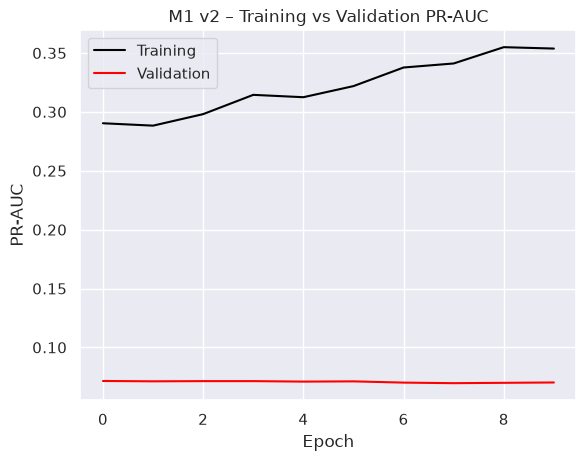

In [35]:
plt.plot(history_m1_v2.history['pr_auc'], color="black", label="Training")
plt.plot(history_m1_v2.history['val_pr_auc'], color="red", label="Validation")
plt.ylabel("PR-AUC")
plt.xlabel("Epoch")
plt.title("M1 v2 – Training vs Validation PR-AUC")
plt.legend()
plt.show()

# Model 2 videometadata 

In [ ]:
# M2'nin iki input’u var: video metni ve kategori. Hocanın kullandığı Sequential yapısı sadece tek input kabul ediyor. Bu yüzden burada Keras’ın Functional API’sini kullan. Mantık aynı, sadece katmanları birbirine elle bağlıyoruz.
# use concatenate layer because 

In [38]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Concatenate

# input 1: video text
video_input = Input(shape=(VIDEO_MAX_LEN,), name='video_text')
x = Embedding(input_dim=VOCAB_SIZE, output_dim=32)(video_input)
x = GlobalAveragePooling1D()(x)

# input 2: category (one-hot)
category_input = Input(shape=(X_train_cat.shape[1],), name='category')

# combine both inputs
merged = Concatenate()([x, category_input])
merged = Dropout(0.5)(merged)
merged = Dense(16, activation='relu')(merged)
output = Dense(1, activation='sigmoid')(merged)

model_m2 = Model(inputs=[video_input, category_input], outputs=output)
model_m2.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ video_text          │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 200, 32)   │    640,000 │ video_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ embedding_3[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category            │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 46)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ category[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 46)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 16)        │        752 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         17 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 640,769 (2.44 MB)

 Trainable params: 640,769 (2.44 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compile

In [39]:
model_m2.compile(loss='binary_crossentropy', optimizer='adam',
                 metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc'),
                          tf.keras.metrics.Precision(name='precision'),
                          tf.keras.metrics.Recall(name='recall')])

In [ ]:
#fit

In [40]:
history_m2 = model_m2.fit([X_train_video, X_train_cat], y_train,
                          validation_data=([X_val_video, X_val_cat], y_val),
                          epochs=10, batch_size=256,
                          class_weight=class_weight,
                          verbose=2)

Epoch 1/10
289/289 - 8s - 27ms/step - loss: 0.6738 - pr_auc: 0.0960 - precision: 0.0614 - recall: 0.4617 - val_loss: 0.6410 - val_pr_auc: 0.1125 - val_precision: 0.1424 - val_recall: 0.4233
Epoch 2/10
289/289 - 5s - 19ms/step - loss: 0.6291 - pr_auc: 0.1517 - precision: 0.0806 - recall: 0.5512 - val_loss: 0.6970 - val_pr_auc: 0.1872 - val_precision: 0.0760 - val_recall: 0.6994
Epoch 3/10
289/289 - 7s - 23ms/step - loss: 0.5961 - pr_auc: 0.1837 - precision: 0.0915 - recall: 0.6053 - val_loss: 0.6804 - val_pr_auc: 0.1602 - val_precision: 0.0728 - val_recall: 0.6576
Epoch 4/10
289/289 - 7s - 24ms/step - loss: 0.5785 - pr_auc: 0.2024 - precision: 0.1007 - recall: 0.6254 - val_loss: 0.6600 - val_pr_auc: 0.1699 - val_precision: 0.0782 - val_recall: 0.6031
Epoch 5/10
289/289 - 7s - 23ms/step - loss: 0.5705 - pr_auc: 0.2048 - precision: 0.1031 - recall: 0.6417 - val_loss: 0.6966 - val_pr_auc: 0.1514 - val_precision: 0.0642 - val_recall: 0.6939
Epoch 6/10
289/289 - 7s - 24ms/step - loss: 0.5591

In [ ]:
#evaluate

In [41]:
scores = model_m2.evaluate([X_test_video, X_test_cat], y_test, return_dict=True)
for name, value in scores.items():
    print("%s: %.4f" % (name, value))

548/548 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.6172 - pr_auc: 0.1275 - precision: 0.0635 - recall: 0.5805
loss: 0.6172
pr_auc: 0.1275
precision: 0.0635
recall: 0.5805


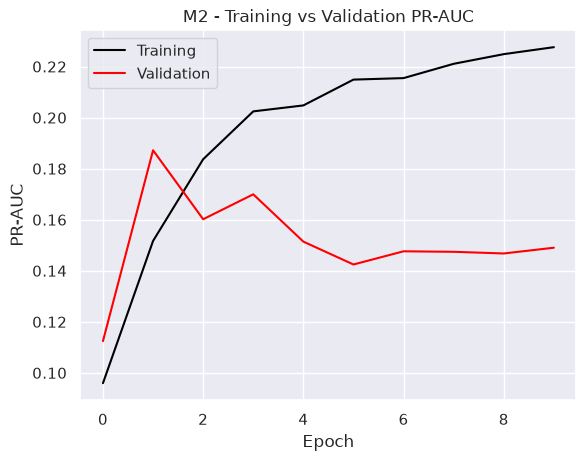

In [43]:
plt.plot(history_m2.history['pr_auc'], color="black", label="Training")
plt.plot(history_m2.history['val_pr_auc'], color="red", label="Validation")
plt.ylabel("PR-AUC")
plt.xlabel("Epoch")
plt.title("M2 - Training vs Validation PR-AUC")
plt.legend()
plt.show()

In [44]:
## M2 results: test PR-AUC 0.1275 (baseline 0.0415), precision 0.0635, recall 0.5805
# Validation PR-AUC peaked at epoch 1 (~0.19) then declined -> mild overfitting after epoch 2
# Video context (G2) is a stronger predictor than comment text alone (M1 ~0.07)

In [ ]:
# Model 3 temporal

In [45]:
# M3 sadece 3 zaman özelliğini kullanıyor (X_*_time). Bunlar sayısal ve zaten ölçeklenmiş, o yüzden Embedding gerekmiyor. Tek input olduğu için Sequential yeterli. Pima örneğindeki gibi basit bir Dense ağ kuruyoruz.

In [46]:
# M3 - Temporal features only (Group 3)

model_m3 = Sequential()
model_m3.add(Input(shape=(X_train_time.shape[1],)))   # 3 temporal features
model_m3.add(Dense(16, activation='relu'))            # hidden layer
model_m3.add(Dropout(0.5))                            # reduce overfitting
model_m3.add(Dense(8, activation='relu'))             # second hidden layer
model_m3.add(Dense(1, activation='sigmoid'))          # binary output
model_m3.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compile & fitting

In [49]:
from tensorflow.keras.metrics import AUC, Precision, Recall

model_m3.compile(optimizer='adam', loss='binary_crossentropy',
                 metrics=[AUC(curve='PR', name='pr_auc'), Precision(name='precision'), Recall(name='recall')])

history_m3 = model_m3.fit(X_train_time, y_train,
                          validation_data=(X_val_time, y_val),
                          epochs=10, batch_size=256,
                          class_weight=class_weight, verbose=2)

Epoch 1/10
289/289 - 2s - 6ms/step - loss: 0.6701 - pr_auc: 0.0709 - precision: 0.0584 - recall: 0.6794 - val_loss: 0.6865 - val_pr_auc: 0.1244 - val_precision: 0.1048 - val_recall: 0.6994
Epoch 2/10
289/289 - 1s - 2ms/step - loss: 0.6611 - pr_auc: 0.0823 - precision: 0.0649 - recall: 0.6298 - val_loss: 0.6782 - val_pr_auc: 0.1268 - val_precision: 0.1093 - val_recall: 0.6703
Epoch 3/10
289/289 - 1s - 2ms/step - loss: 0.6565 - pr_auc: 0.0823 - precision: 0.0693 - recall: 0.6125 - val_loss: 0.6684 - val_pr_auc: 0.1258 - val_precision: 0.1110 - val_recall: 0.6512
Epoch 4/10
289/289 - 1s - 2ms/step - loss: 0.6547 - pr_auc: 0.0842 - precision: 0.0707 - recall: 0.5845 - val_loss: 0.6581 - val_pr_auc: 0.1254 - val_precision: 0.1150 - val_recall: 0.6376
Epoch 5/10
289/289 - 1s - 2ms/step - loss: 0.6532 - pr_auc: 0.0856 - precision: 0.0733 - recall: 0.5852 - val_loss: 0.6609 - val_pr_auc: 0.1253 - val_precision: 0.1148 - val_recall: 0.6303
Epoch 6/10
289/289 - 1s - 2ms/step - loss: 0.6495 - pr_

In [ ]:
# evaluate

In [50]:
scores = model_m3.evaluate(X_test_time, y_test, return_dict=True)
for name, value in scores.items():
    print(f"{name}: {value:.4f}")

548/548 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6024 - pr_auc: 0.1681 - precision: 0.0951 - recall: 0.6176
loss: 0.6024
pr_auc: 0.1681
precision: 0.0951
recall: 0.6176


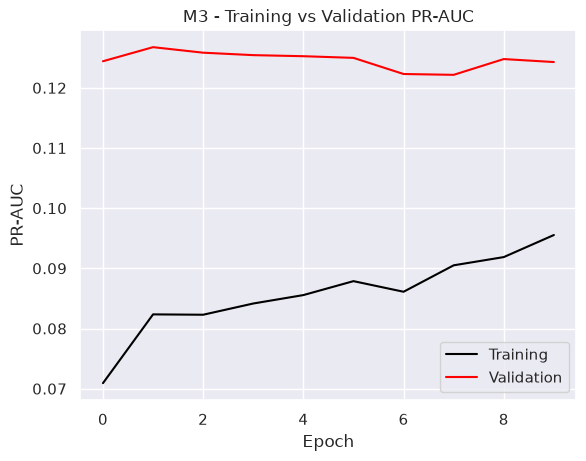

In [51]:
plt.plot(history_m3.history['pr_auc'], color="black", label="Training")
plt.plot(history_m3.history['val_pr_auc'], color="red", label="Validation")
plt.ylabel("PR-AUC")
plt.xlabel("Epoch")
plt.title("M3 - Training vs Validation PR-AUC")
plt.legend()
plt.show()

In [ ]:
#Model 4 - All groups combined (G1 + G2 + G3)

In [52]:
# Branch 1: comment text (Group 1)
comment_input = Input(shape=(COMMENT_MAX_LEN,), name='comment_text')
c = Embedding(input_dim=VOCAB_SIZE, output_dim=32)(comment_input)
c = GlobalAveragePooling1D()(c)

# Branch 2: video text (Group 2)
video_input = Input(shape=(VIDEO_MAX_LEN,), name='video_text')
v = Embedding(input_dim=VOCAB_SIZE, output_dim=32)(video_input)
v = GlobalAveragePooling1D()(v)

# Branch 3: video category (Group 2)
category_input = Input(shape=(X_train_cat.shape[1],), name='category')

# Branch 4: temporal features (Group 3)
time_input = Input(shape=(X_train_time.shape[1],), name='time')

# Merge all branches
merged = Concatenate()([c, v, category_input, time_input])
merged = Dropout(0.5)(merged)
merged = Dense(16, activation='relu')(merged)
output = Dense(1, activation='sigmoid')(merged)

model_m4 = Model(inputs=[comment_input, video_input, category_input, time_input], outputs=output)
model_m4.summary()

Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ comment_text        │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ video_text          │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 30, 32)    │    640,000 │ comment_text[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 200, 32)   │    640,000 │ video_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ embedding_4[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ embedding_5[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category            │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time (InputLayer)   │ (None, 3)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 81)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
│                     │                   │            │ category[0][0],   │
│                     │                   │            │ time[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 81)        │          0 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 16)        │      1,312 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 1)         │         17 │ dense_11[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,281,329 (4.89 MB)

 Trainable params: 1,281,329 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compile & fitting

In [53]:
model_m4.compile(optimizer='adam', loss='binary_crossentropy',
                 metrics=[AUC(curve='PR', name='pr_auc'), Precision(name='precision'), Recall(name='recall')])

history_m4 = model_m4.fit([X_train_comment, X_train_video, X_train_cat, X_train_time], y_train,
                          validation_data=([X_val_comment, X_val_video, X_val_cat, X_val_time], y_val),
                          epochs=10, batch_size=256,
                          class_weight=class_weight, verbose=2)

Epoch 1/10
289/289 - 6s - 19ms/step - loss: 0.6653 - pr_auc: 0.0846 - precision: 0.0682 - recall: 0.4569 - val_loss: 0.6441 - val_pr_auc: 0.2151 - val_precision: 0.1223 - val_recall: 0.8120
Epoch 2/10
289/289 - 4s - 14ms/step - loss: 0.6059 - pr_auc: 0.1719 - precision: 0.0892 - recall: 0.6040 - val_loss: 0.6552 - val_pr_auc: 0.1716 - val_precision: 0.1201 - val_recall: 0.8038
Epoch 3/10
289/289 - 4s - 14ms/step - loss: 0.5759 - pr_auc: 0.1913 - precision: 0.1004 - recall: 0.6455 - val_loss: 0.6750 - val_pr_auc: 0.1774 - val_precision: 0.1116 - val_recall: 0.7866
Epoch 4/10
289/289 - 4s - 16ms/step - loss: 0.5496 - pr_auc: 0.2220 - precision: 0.1085 - recall: 0.6804 - val_loss: 0.6688 - val_pr_auc: 0.1674 - val_precision: 0.1088 - val_recall: 0.7366
Epoch 5/10
289/289 - 4s - 15ms/step - loss: 0.5294 - pr_auc: 0.2385 - precision: 0.1180 - recall: 0.7024 - val_loss: 0.6828 - val_pr_auc: 0.1394 - val_precision: 0.1013 - val_recall: 0.7012
Epoch 6/10
289/289 - 4s - 15ms/step - loss: 0.5033

In [ ]:
# evaluate

In [54]:
scores = model_m4.evaluate([X_test_comment, X_test_video, X_test_cat, X_test_time], y_test, return_dict=True)
for name, value in scores.items():
    print(f"{name}: {value:.4f}")

548/548 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5481 - pr_auc: 0.0920 - precision: 0.0770 - recall: 0.5034
loss: 0.5481
pr_auc: 0.0920
precision: 0.0770
recall: 0.5034


In [ ]:
# graph

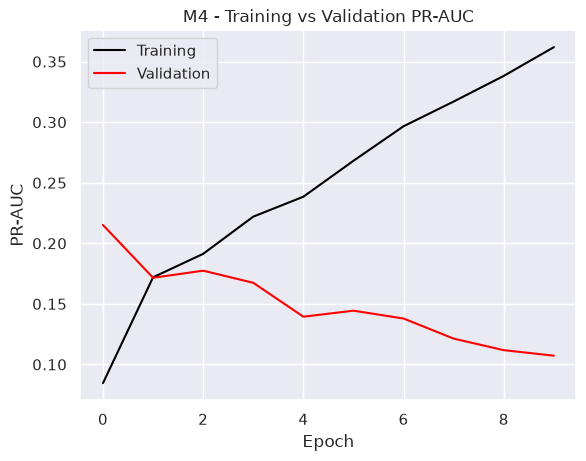

In [55]:
plt.plot(history_m4.history['pr_auc'], color="black", label="Training")
plt.plot(history_m4.history['val_pr_auc'], color="red", label="Validation")
plt.ylabel("PR-AUC")
plt.xlabel("Epoch")
plt.title("M4 - Training vs Validation PR-AUC")
plt.legend()
plt.show()

In [ ]:
# v1 results: test PR-AUC = 0.0920, precision = 0.0770, recall = 0.5034 (overfitting after epoch 1)

In [ ]:
# M1 v2

In [58]:
# M4 v2 - same architecture as v1, with EarlyStopping
# v1 results: test PR-AUC = 0.0920, precision = 0.0770, recall = 0.5034 (overfitting after epoch 1)
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_pr_auc', mode='max', patience=3, restore_best_weights=True)

# Branch 1: comment text (Group 1)
comment_input = Input(shape=(COMMENT_MAX_LEN,), name='comment_text')
c = Embedding(input_dim=VOCAB_SIZE, output_dim=32)(comment_input)
c = GlobalAveragePooling1D()(c)

# Branch 2: video text (Group 2)
video_input = Input(shape=(VIDEO_MAX_LEN,), name='video_text')
v = Embedding(input_dim=VOCAB_SIZE, output_dim=32)(video_input)
v = GlobalAveragePooling1D()(v)

# Branch 3: video category (Group 2)
category_input = Input(shape=(X_train_cat.shape[1],), name='category')

# Branch 4: temporal features (Group 3)
time_input = Input(shape=(X_train_time.shape[1],), name='time')

# Merge all branches
merged = Concatenate()([c, v, category_input, time_input])
merged = Dropout(0.5)(merged)
merged = Dense(16, activation='relu')(merged)
output = Dense(1, activation='sigmoid')(merged)

model_m4_v2 = Model(inputs=[comment_input, video_input, category_input, time_input], outputs=output)
model_m4_v2.summary()

Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ comment_text        │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ video_text          │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 30, 32)    │    640,000 │ comment_text[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_7         │ (None, 200, 32)   │    640,000 │ video_text[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ embedding_6[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ embedding_7[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category            │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time (InputLayer)   │ (None, 3)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 81)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
│                     │                   │            │ category[0][0],   │
│                     │                   │            │ time[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 81)        │          0 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 16)        │      1,312 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 1)         │         17 │ dense_13[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,281,329 (4.89 MB)

 Trainable params: 1,281,329 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:
model_m4_v2.compile(optimizer='adam', loss='binary_crossentropy',
                    metrics=[AUC(curve='PR', name='pr_auc'), Precision(name='precision'), Recall(name='recall')])

history_m4_v2 = model_m4_v2.fit([X_train_comment, X_train_video, X_train_cat, X_train_time], y_train,
                                validation_data=([X_val_comment, X_val_video, X_val_cat, X_val_time], y_val),
                                epochs=20, batch_size=256,
                                class_weight=class_weight, callbacks=[early_stop], verbose=2)

Epoch 1/20
289/289 - 6s - 20ms/step - loss: 0.6749 - pr_auc: 0.0838 - precision: 0.0639 - recall: 0.4488 - val_loss: 0.6452 - val_pr_auc: 0.1719 - val_precision: 0.1238 - val_recall: 0.7430
Epoch 2/20
289/289 - 4s - 15ms/step - loss: 0.6181 - pr_auc: 0.1550 - precision: 0.0856 - recall: 0.5842 - val_loss: 0.6573 - val_pr_auc: 0.1811 - val_precision: 0.1186 - val_recall: 0.8002
Epoch 3/20
289/289 - 4s - 15ms/step - loss: 0.5845 - pr_auc: 0.1854 - precision: 0.0954 - recall: 0.6226 - val_loss: 0.6555 - val_pr_auc: 0.2005 - val_precision: 0.1234 - val_recall: 0.7784
Epoch 4/20
289/289 - 5s - 18ms/step - loss: 0.5563 - pr_auc: 0.2153 - precision: 0.1091 - recall: 0.6725 - val_loss: 0.6840 - val_pr_auc: 0.1751 - val_precision: 0.1114 - val_recall: 0.7811
Epoch 5/20
289/289 - 4s - 14ms/step - loss: 0.5347 - pr_auc: 0.2314 - precision: 0.1168 - recall: 0.6996 - val_loss: 0.6186 - val_pr_auc: 0.1644 - val_precision: 0.1276 - val_recall: 0.6294
Epoch 6/20
289/289 - 4s - 14ms/step - loss: 0.5088

In [60]:
scores = model_m4_v2.evaluate([X_test_comment, X_test_video, X_test_cat, X_test_time], y_test, return_dict=True)
for name, value in scores.items():
    print(f"{name}: {value:.4f}")

548/548 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6199 - pr_auc: 0.1517 - precision: 0.0872 - recall: 0.7098
loss: 0.6199
pr_auc: 0.1517
precision: 0.0872
recall: 0.7098


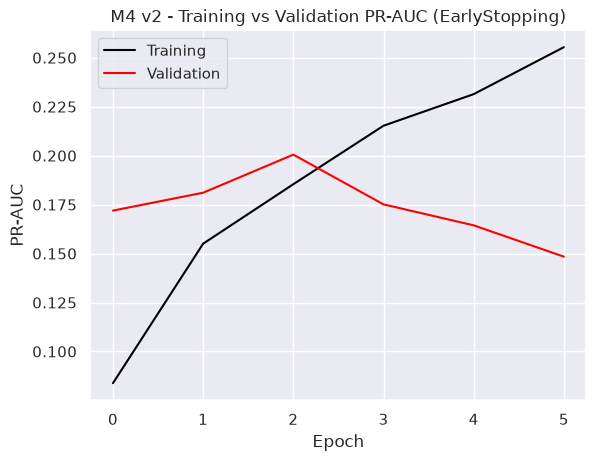

In [61]:
plt.plot(history_m4_v2.history['pr_auc'], color="black", label="Training")
plt.plot(history_m4_v2.history['val_pr_auc'], color="red", label="Validation")
plt.ylabel("PR-AUC")
plt.xlabel("Epoch")
plt.title("M4 v2 - Training vs Validation PR-AUC (EarlyStopping)")
plt.legend()
plt.show()